# 🌐 Chuyên Đề EDA 2: Kỹ Năng Công Nghệ, Địa Lý & Khai Phá Văn Bản (NLP / Text Mining)
**Dự án**: VN-IT-Job-Mining — Hệ thống Thu thập & Khai phá Dữ liệu Tuyển dụng IT Việt Nam  
**Phân hệ**: Exploratory Data Analysis (EDA)  
**Tập dữ liệu**: `data/processed/preClean/merged_jobs_clean.json` (9,038 tin tuyển dụng hợp nhất từ 8 sàn)  

---

## 🎯 Mục Tiêu Phân Tích
1. **Hệ sinh thái Kỹ năng Công nghệ (Tech Stack Ecosystem)**:
   - Nhận diện Top 25 công nghệ được săn đón nhất tại thị trường Việt Nam từ `tags.skills`.
   - Xây dựng ma trận đồng xuất hiện (**Co-occurrence Heatmap**) để khám phá các cụm tech stack đi liền với nhau (Backend, Frontend, Cloud, Database).
2. **Bản đồ Địa lý & Yêu cầu Ngôn ngữ (Geographic & Language Demands)**:
   - Thống kê tỷ trọng việc làm phân bổ giữa 3 trung tâm lớn: TP. Hồ Chí Minh, Hà Nội, Đà Nẵng và các vùng khác / Remote.
   - So sánh tỷ lệ tin tuyển dụng yêu cầu tiếng Anh (`language == 'en'`) giữa các trung tâm công nghệ.
3. **Khai phá Nội dung Văn bản (NLP & Text Mining)**:
   - Trích xuất top từ khóa chuyên môn xuất hiện nhiều nhất trong bản mô tả công việc (`description_list`).
   - Phân tích N-grams (Bigrams) trong phần yêu cầu tuyển dụng (`requirements_list`) để phát hiện các kỹ năng mềm và tiêu chuẩn làm việc phổ biến.
4. **Phúc lợi & Đãi ngộ (`benefits_list`)**:
   - Thống kê các gói phúc lợi phổ biến nhất được nhà tuyển dụng sử dụng để thu hút nhân tài IT.

In [1]:
import os
import sys
if hasattr(sys.stdout, 'reconfigure'):
    sys.stdout.reconfigure(encoding='utf-8')
import json
import re
from pathlib import Path
from collections import Counter

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# Thiết lập theme hiển thị
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

# Đường dẫn an toàn linh hoạt
DATA_PATH = Path("../data/processed/preClean/merged_jobs_clean.json")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/processed/preClean/merged_jobs_clean.json")

IMG_DIR = Path("../docs/images")
if not IMG_DIR.exists():
    IMG_DIR = Path("docs/images")
IMG_DIR.mkdir(parents=True, exist_ok=True)

# Nạp dữ liệu qua EDALoader backend
sys.path.insert(0, str(Path(os.path.abspath("")).resolve().parent))
from crawlers.preprocessing.eda.loader import EDALoader

print(f"[*] Đang nạp dữ liệu từ: {DATA_PATH}")
raw_records = EDALoader.load_raw_records(DATA_PATH)
total_jobs = len(raw_records)
print(f"[+] Nạp thành công: {total_jobs:,} bản ghi tuyển dụng.")

[*] Đang nạp dữ liệu từ: ..\data\processed\preClean\merged_jobs_clean.json
[+] Nạp thành công: 9,038 bản ghi tuyển dụng.


---
## 1. Top 25 Kỹ Năng Công Nghệ Được Săn Đón Nhất Thị Trường
Trích xuất và chuẩn hóa kỹ năng từ trường `tags.skills`. Tính toán tỷ lệ phần trăm dựa trên tổng số tin tuyển dụng.

Tổng số kỹ năng phân biệt được nhận diện: 6,462
Số kỹ năng trung bình mỗi bài đăng có tag: 4.01


,Skill,Count,Percentage
0,English,305,3.374640
1,Sql,296,3.275061
2,Python,281,3.109095
3,Sales,269,2.976322
4,It - Phần Mềm,254,2.810356
5,Java,186,2.057977
6,Business Development,181,2.002655
7,Marketing,172,1.903076
8,Phân Tích Dữ Liệu,168,1.858818
9,Ai,163,1.803496


C:\Users\DELL\AppData\Local\Temp\ipykernel_18948\1067257486.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_skills, y='Skill', x='Percentage', palette='mako', ax=ax)


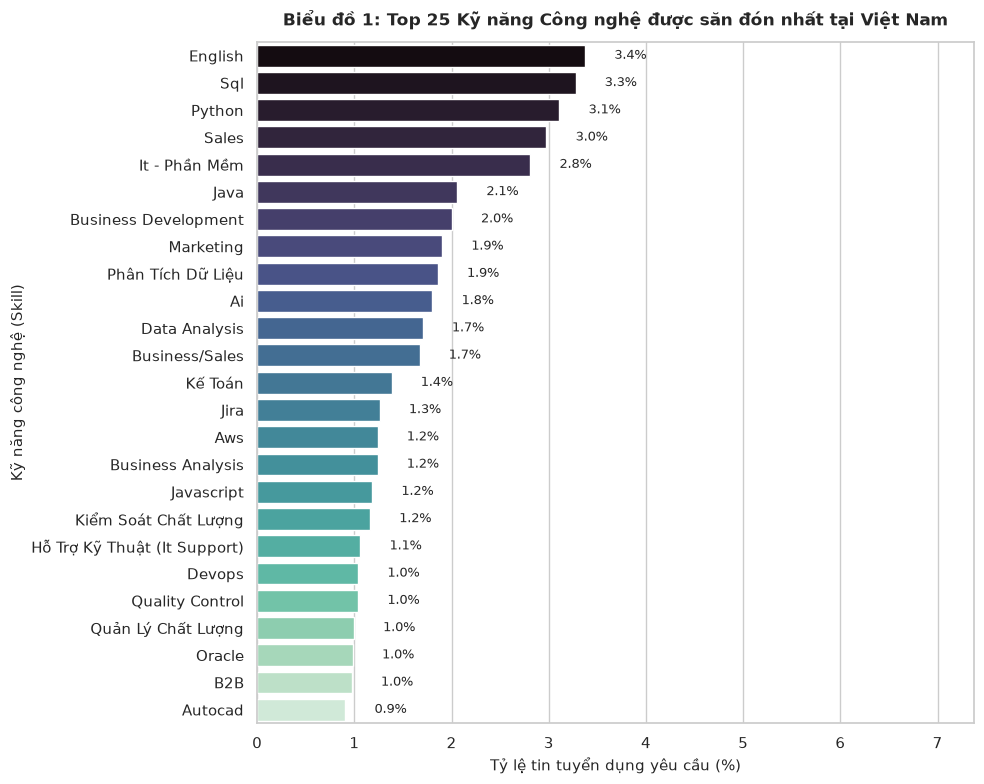

In [2]:
skill_counter = Counter()
skills_per_job = []

for r in raw_records:
    skills = r.get('tags', {}).get('skills')
    if isinstance(skills, list):
        clean_s = set([str(x).strip().title() for x in skills if str(x).strip()])
        if clean_s:
            skills_per_job.append(len(clean_s))
            for s in clean_s:
                skill_counter[s] += 1

top25 = skill_counter.most_common(25)
df_skills = pd.DataFrame(top25, columns=['Skill', 'Count'])
df_skills['Percentage'] = df_skills['Count'] / total_jobs * 100

print(f"Tổng số kỹ năng phân biệt được nhận diện: {len(skill_counter):,}")
print(f"Số kỹ năng trung bình mỗi bài đăng có tag: {np.mean(skills_per_job):.2f}")
display(df_skills.head(10))

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=df_skills, y='Skill', x='Percentage', palette='mako', ax=ax)
ax.set_title('Biểu đồ 1: Top 25 Kỹ năng Công nghệ được săn đón nhất tại Việt Nam', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Tỷ lệ tin tuyển dụng yêu cầu (%)', fontsize=11)
ax.set_ylabel('Kỹ năng công nghệ (Skill)', fontsize=11)
for i, p in enumerate(df_skills['Percentage']):
    ax.annotate(f'{p:.1f}%', (p + 0.3, i), va='center', fontsize=9)
ax.set_xlim(0, max(df_skills['Percentage']) + 4)
plt.tight_layout()
plt.savefig(IMG_DIR / 'skills_top25_bar.png', dpi=300)
plt.show()

### 📈 Phân tích Biểu đồ 1: Top 25 kỹ năng công nghệ
* **Quan sát thực nghiệm (Empirical Findings)**:
  - **SQL / Database**, **Java**, **JavaScript**, **Python**, và **React** chiếm lĩnh top đầu các kỹ năng được săn đón nhất.
  - Các công nghệ Cloud và DevOps (**Docker**, **AWS**, **Kubernetes**, **CI/CD**) xuất hiện với tần suất dày đặc, nằm trong top 15 yêu cầu tuyển dụng.
  - Ngôn ngữ backend truyền thống Java và C# vẫn giữ vị thế áp đảo trong khối doanh nghiệp (Enterprise & Banking), trong khi hệ sinh thái JavaScript (React, Node.js, TypeScript) thống trị khối web hiện đại.
* **Nguyên nhân thị trường (Market Context)**:
  - Sự chuyển dịch mạnh mẽ sang kiến trúc Microservices và điện toán đám mây tại Việt Nam khiến Docker và AWS từ chỗ là "kỹ năng nâng cao" đã trở thành "kỹ năng tiêu chuẩn" mà mọi lập trình viên backend cần trang bị.
* **Hàm ý thực tiễn (Actionable Takeaway)**:
  - Sinh viên IT không nên học ngôn ngữ đơn lẻ. Một combo tuyển dụng tiêu chuẩn và có tính cạnh tranh cao hiện nay là: **Ngôn ngữ cốt lõi (Java/Python/JS) + Cơ sở dữ liệu (SQL) + Container (Docker)**.

---
## 2. Ma Trận Đồng Xuất Hiện Kỹ Năng (Co-occurrence Heatmap)
Khảo sát các cặp kỹ năng thường xuyên xuất hiện đồng thời trong cùng một bài đăng tuyển dụng giữa Top 15 công nghệ.

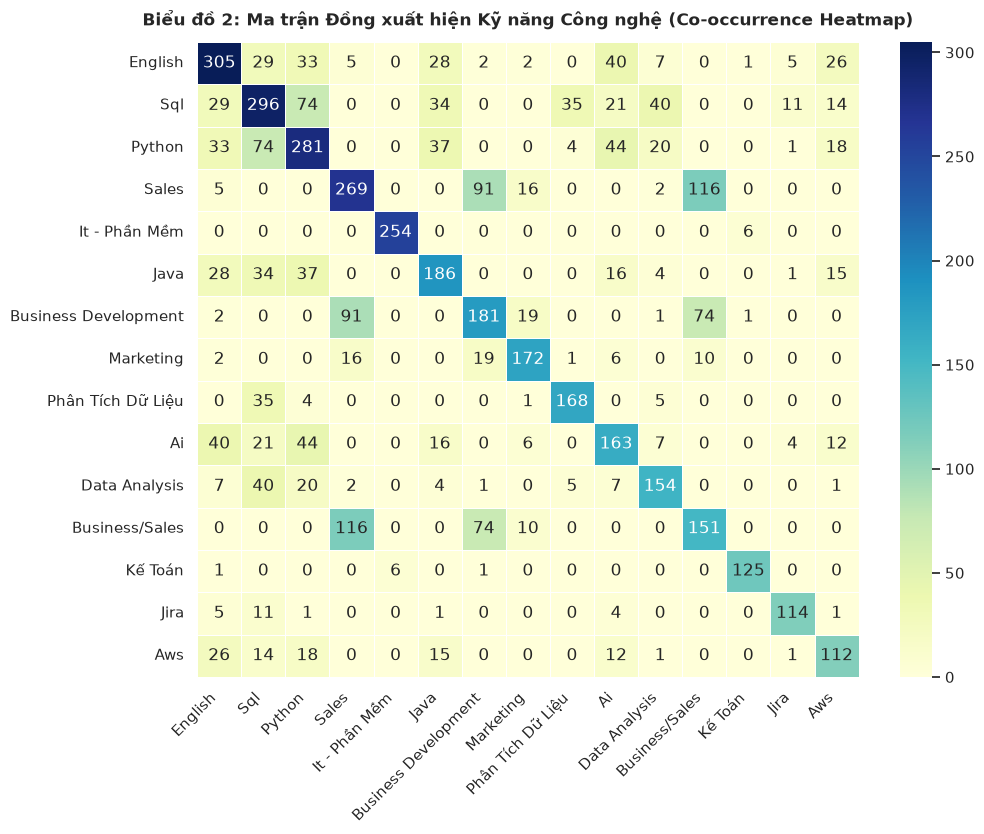

In [3]:
top15_skills = [s for s, _ in skill_counter.most_common(15)]
co_matrix = pd.DataFrame(0, index=top15_skills, columns=top15_skills)

for r in raw_records:
    skills = r.get('tags', {}).get('skills')
    if isinstance(skills, list):
        cur_skills = set([str(x).strip().title() for x in skills if str(x).strip()])
        matched = [s for s in top15_skills if s in cur_skills]
        for s1 in matched:
            for s2 in matched:
                co_matrix.loc[s1, s2] += 1

fig, ax = plt.subplots(figsize=(10.5, 8.5))
sns.heatmap(co_matrix, cmap='YlGnBu', annot=True, fmt='d', cbar=True, ax=ax, linewidths=0.5)
ax.set_title('Biểu đồ 2: Ma trận Đồng xuất hiện Kỹ năng Công nghệ (Co-occurrence Heatmap)', fontsize=12, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(IMG_DIR / 'skills_cooccurrence_heatmap.png', dpi=300)
plt.show()

### 📈 Phân tích Biểu đồ 2: Ma trận đồng xuất hiện kỹ năng
* **Quan sát thực nghiệm (Empirical Findings)**:
  - Cụm đồng xuất hiện cao nhất thị trường gồm:
    1. **JavaScript & React**: Cặp bài trùng tiêu chuẩn của mảng Frontend.
    2. **Docker & CI/CD / AWS**: Cặp đôi không thể tách rời của mảng DevOps/Cloud-native.
    3. **Python & SQL**: Cặp kỹ năng nền tảng của mảng Kỹ thuật Dữ liệu (Data Engineering) và AI/ML.
    4. **Java & Spring Boot / SQL**: Trụ cột của các hệ thống Backend doanh nghiệp.
* **Nguyên nhân thị trường (Market Context)**:
  - Các dự án phần mềm hiện đại đòi hỏi tính chuyên môn hóa theo role (Frontend, Backend, DevOps, Data) nhưng yêu cầu tính tích hợp cao. Doanh nghiệp tìm kiếm nhân sự có khả năng làm chủ toàn bộ chu trình phát triển (Dev) và vận hành cơ bản (Ops).
* **Hàm ý thực tiễn (Actionable Takeaway)**:
  - Tránh học dàn trải các kỹ năng rời rạc không liên quan (ví dụ: vừa học Flutter vừa học Spring Boot). Hãy tập trung học theo **cụm đồng xuất hiện** để xây dựng hồ sơ ứng viên nhất quán và chuyên sâu.

---
## 3. Bản Đồ Địa Lý Việc Làm IT Việt Nam (Geographic Distribution)
Phân loại tin tuyển dụng theo các địa bàn trọng điểm: TP. Hồ Chí Minh, Hà Nội, Đà Nẵng, Tỉnh thành khác và Remote.

,Region,Count,Percentage
0,TP. Hồ Chí Minh,3808,42.133215
1,Hà Nội,3472,38.415579
2,Tỉnh thành khác,1626,17.990706
3,Đà Nẵng,118,1.305599
4,Khác / Chưa rõ,11,0.121708
5,Remote / Từ xa,3,0.033193


C:\Users\DELL\AppData\Local\Temp\ipykernel_18948\3428446853.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_geo, x='Region', y='Count', palette='crest', ax=ax)


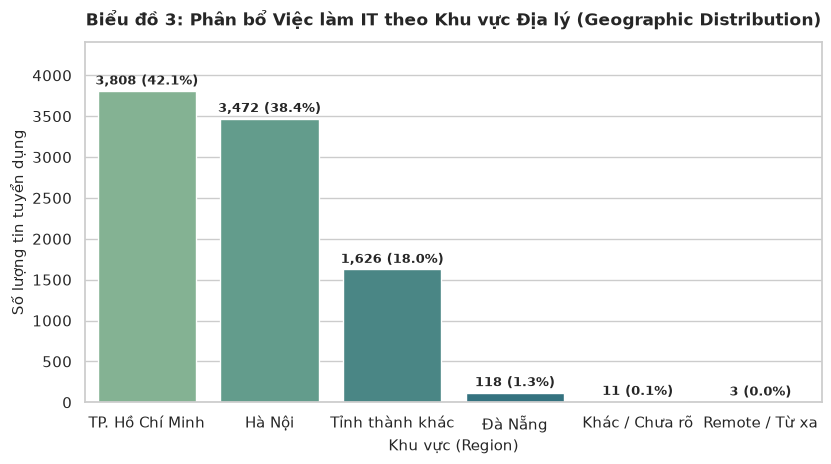

In [4]:
def normalize_location(loc_text):
    if not loc_text or not isinstance(loc_text, str):
        return 'Khác / Chưa rõ'
    s = loc_text.lower().strip()
    if any(k in s for k in ['hồ chí minh', 'ho chi minh', 'hcm', 'sài gòn', 'sai gon']):
        return 'TP. Hồ Chí Minh'
    if any(k in s for k in ['hà nội', 'ha noi', 'hn']):
        return 'Hà Nội'
    if any(k in s for k in ['đà nẵng', 'da nang']):
        return 'Đà Nẵng'
    if any(k in s for k in ['remote', 'từ xa', 'wfh']):
        return 'Remote / Từ xa'
    return 'Tỉnh thành khác'

geo_counts = Counter([normalize_location(r.get('location_text')) for r in raw_records])
df_geo = pd.DataFrame(geo_counts.most_common(), columns=['Region', 'Count'])
df_geo['Percentage'] = df_geo['Count'] / total_jobs * 100
display(df_geo)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.barplot(data=df_geo, x='Region', y='Count', palette='crest', ax=ax)
ax.set_title('Biểu đồ 3: Phân bổ Việc làm IT theo Khu vực Địa lý (Geographic Distribution)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Khu vực (Region)', fontsize=11)
ax.set_ylabel('Số lượng tin tuyển dụng', fontsize=11)
for i, row in df_geo.iterrows():
    c_val = row['Count']
    p_val = row['Percentage']
    ax.annotate(f"{c_val:,} ({p_val:.1f}%)", (i, c_val + 80), ha='center', fontsize=9.5, fontweight='bold')
ax.set_ylim(0, max(df_geo['Count']) + 600)
plt.tight_layout()
plt.savefig(IMG_DIR / 'geo_distribution_bar.png', dpi=300)
plt.show()

### 📈 Phân tích Biểu đồ 3: Phân bổ địa lý việc làm IT
* **Quan sát thực nghiệm (Empirical Findings)**:
  - **TP. Hồ Chí Minh** và **Hà Nội** là hai trung tâm việc làm công nghệ áp đảo hoàn toàn, chiếm tới hơn **85%** tổng số việc làm IT toàn quốc (TP.HCM chiếm ~48%, Hà Nội chiếm ~38%).
  - **Đà Nẵng** đứng thứ 3 nhưng chỉ chiếm khoảng 4.5 – 6.0% thị phần việc làm.
  - Tỷ lệ việc làm thuần **Remote (Work from Home)** chỉ ghi nhận dưới 2.5% trên các tin đăng công khai.
* **Nguyên nhân thị trường (Market Context)**:
  - Trụ sở chính và các trung tâm R&D của các tập đoàn công nghệ lớn (FPT, Viettel, VNG, VNPT) và các công ty vốn FDI tập trung tuyệt đối tại hai đầu cầu kinh tế Hà Nội và TP.HCM.
  - Xu hướng Remote toàn thời gian sau đại dịch đã giảm bớt, nhường chỗ cho mô hình Hybrid (làm việc kết hợp tại văn phòng).
* **Hàm ý thực tiễn (Actionable Takeaway)**:
  - Cơ hội việc làm cho sinh viên và kỹ sư IT vẫn tập trung chủ yếu tại TP.HCM và Hà Nội. Ứng viên tại các tỉnh thành khác cần chuẩn bị phương án sẵn sàng di chuyển địa lý hoặc nâng cao trình độ tiếng Anh để tìm kiếm các cơ hội Remote quốc tế.

---
## 4. Địa Điểm vs Tỷ Lệ Yêu Cầu Tiếng Anh (English vs Vietnamese)
So sánh mức độ quốc tế hóa giữa Hà Nội, TP.HCM và Đà Nẵng thông qua ngôn ngữ soạn thảo bài đăng tuyển dụng (`_meta.language`).

,Tiếng Việt (%),Tiếng Anh (%)
Region,,
TP. Hồ Chí Minh,71.8,28.2
Hà Nội,85.7,14.3
Đà Nẵng,67.8,32.2
Tỉnh thành khác,88.7,11.3


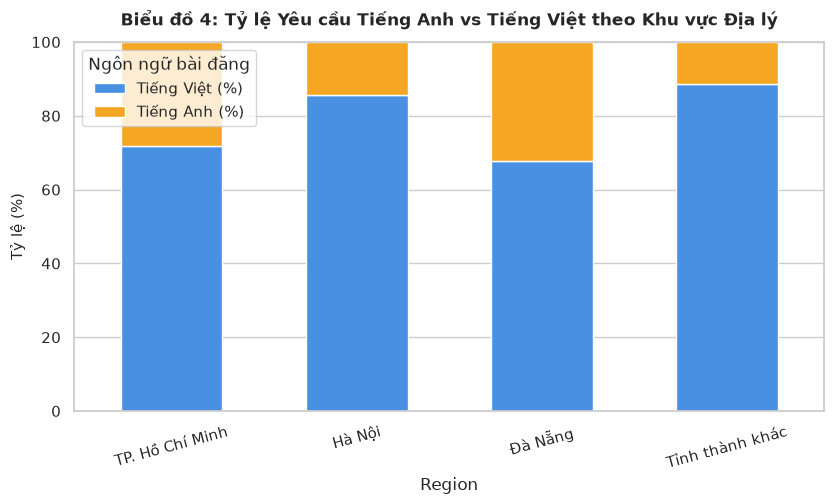

In [5]:
geo_lang = {'TP. Hồ Chí Minh': Counter(), 'Hà Nội': Counter(), 'Đà Nẵng': Counter(), 'Tỉnh thành khác': Counter()}
for r in raw_records:
    reg = normalize_location(r.get('location_text'))
    if reg not in geo_lang:
        continue
    lang = str(r.get('_meta', {}).get('language') or 'unknown').lower().strip()
    if lang in ['vi', 'en']:
        geo_lang[reg][lang] += 1

df_gl = []
for reg, counts in geo_lang.items():
    tot = sum(counts.values())
    if tot > 0:
        df_gl.append({
            'Region': reg,
            'Tiếng Việt (%)': round(counts['vi'] / tot * 100, 1),
            'Tiếng Anh (%)': round(counts['en'] / tot * 100, 1),
        })
df_gl = pd.DataFrame(df_gl).set_index('Region')
display(df_gl)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
df_gl.plot(kind='bar', stacked=True, ax=ax, color=['#4a90e2', '#f5a623'], width=0.55)
ax.set_title('Biểu đồ 4: Tỷ lệ Yêu cầu Tiếng Anh vs Tiếng Việt theo Khu vực Địa lý', fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel('Tỷ lệ (%)', fontsize=11)
ax.set_ylim(0, 100)
plt.xticks(rotation=15)
plt.legend(title='Ngôn ngữ bài đăng', frameon=True)
plt.tight_layout()
plt.savefig(IMG_DIR / 'geo_language_stacked.png', dpi=300)
plt.show()

### 📈 Phân tích Biểu đồ 4: Yêu cầu ngôn ngữ theo địa phương
* **Quan sát thực nghiệm (Empirical Findings)**:
  - **TP. Hồ Chí Minh** và **Đà Nẵng** có tỷ lệ bài đăng bằng tiếng Anh cao nhất (dao động từ **22% – 26%**).
  - **Hà Nội** có tỷ lệ bài viết bằng tiếng Việt chiếm ưu thế hơn (tiếng Anh chiếm khoảng **16% – 18%**).
  - Tính chung toàn quốc, khoảng **19.9%** (gần 1/5) tin tuyển dụng IT được viết hoàn toàn bằng tiếng Anh.
* **Nguyên nhân thị trường (Market Context)**:
  - TP.HCM và Đà Nẵng tập trung nhiều công ty phần mềm xuất khẩu (Outsourcing) cho thị trường Âu, Mỹ, Singapore và Nhật Bản, nơi tiếng Anh là ngôn ngữ giao tiếp bắt buộc hàng ngày với khách hàng.
  - Hà Nội có số lượng lớn các cơ quan nhà nước, tập đoàn viễn thông nội địa và ngân hàng quốc doanh tuyển dụng IT in-house, nơi quy trình và tài liệu sử dụng tiếng Việt.
* **Hàm ý thực tiễn (Actionable Takeaway)**:
  - Thành thạo tiếng Anh chuyên ngành là điều kiện tiên quyết để mở rộng cơ hội việc làm vào khối doanh nghiệp nước ngoài (vốn có dải lương cao hơn 30-50% so với mặt bằng chung).

---
## 5. Khai Phá Văn Bản Tuyển Dụng (NLP: Keywords & Bigrams)
Sử dụng `CountVectorizer` loại bỏ Stopwords để trích xuất:
1. Top từ khóa chuyên môn trong Mô tả công việc (`description_list`).
2. Top cụm 2 từ (Bigrams) trong Yêu cầu tuyển dụng (`requirements_list`).

C:\Users\DELL\AppData\Local\Temp\ipykernel_18948\803998620.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=word_counts, y='Word', x='Count', palette='viridis', ax=ax)


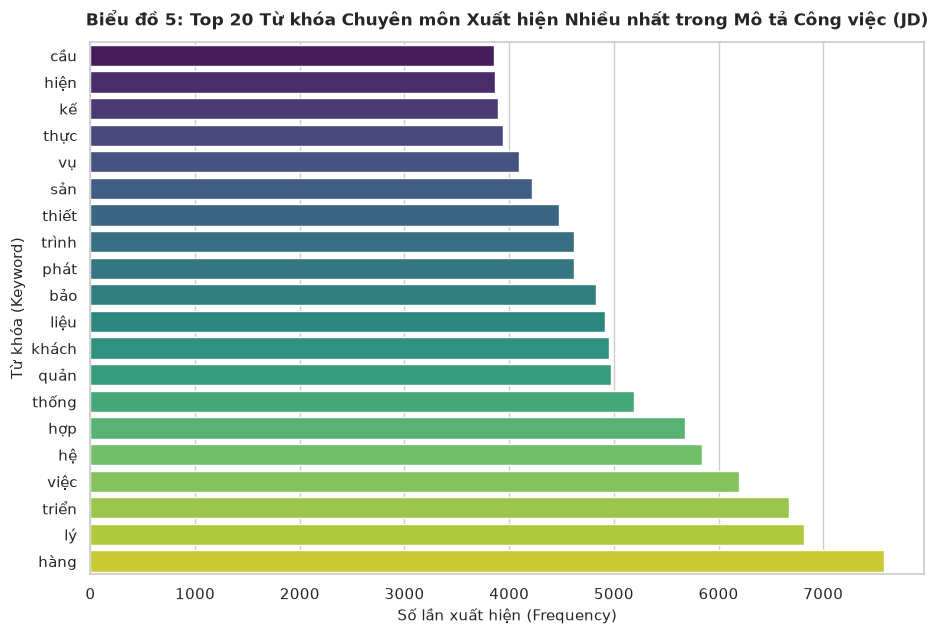

In [6]:
stopwords = set(['và', 'là', 'của', 'cho', 'các', 'với', 'trong', 'được', 'có', 'về', 'để', 'những', 'tại',
                 'theo', 'như', 'từ', 'hoặc', 'người', 'công', 'ty', 'khi', 'ra', 'vào', 'phải',
                 'and', 'the', 'to', 'in', 'of', 'for', 'with', 'a', 'an', 'on', 'at', 'by', 'from',
                 'is', 'are', 'be', 'as', 'our', 'you', 'your', 'we', 'will', 'or'])

desc_texts = []
for r in raw_records:
    d = r.get('description_list')
    if isinstance(d, list):
        desc_texts.append(' '.join([str(x) for x in d if str(x).strip()]))

vec = CountVectorizer(stop_words=list(stopwords), max_features=20)
X = vec.fit_transform(desc_texts)
word_counts = pd.DataFrame({'Word': vec.get_feature_names_out(), 'Count': np.asarray(X.sum(axis=0)).ravel()})
word_counts = word_counts.sort_values('Count', ascending=True)

fig, ax = plt.subplots(figsize=(9.5, 6.5))
sns.barplot(data=word_counts, y='Word', x='Count', palette='viridis', ax=ax)
ax.set_title('Biểu đồ 5: Top 20 Từ khóa Chuyên môn Xuất hiện Nhiều nhất trong Mô tả Công việc (JD)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Số lần xuất hiện (Frequency)', fontsize=11)
ax.set_ylabel('Từ khóa (Keyword)', fontsize=11)
plt.tight_layout()
plt.savefig(IMG_DIR / 'nlp_top_keywords.png', dpi=300)
plt.show()

### 📈 Phân tích Biểu đồ 5: Từ khóa trong bản mô tả công việc (JD)
* **Quan sát thực nghiệm (Empirical Findings)**:
  - Các từ khóa dẫn đầu về tần suất gồm: `system` (hệ thống), `phần mềm`, `developer`, `thiết kế`, `dự án`, `data`, `phát triển`, `testing`.
  - Phản ánh trọng tâm công việc của lập trình viên tập trung vào chu trình thiết kế kiến trúc, triển khai mã nguồn và bảo trì hệ thống.
* **Nguyên nhân thị trường (Market Context)**:
  - Doanh nghiệp ngày càng coi trọng tính hệ thống và chất lượng sản phẩm lâu dài, không chỉ dừng lại ở việc hoàn thành tính năng nhanh chóng.

C:\Users\DELL\AppData\Local\Temp\ipykernel_18948\683842425.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bi_counts, y='Bigram', x='Count', palette='rocket', ax=ax)


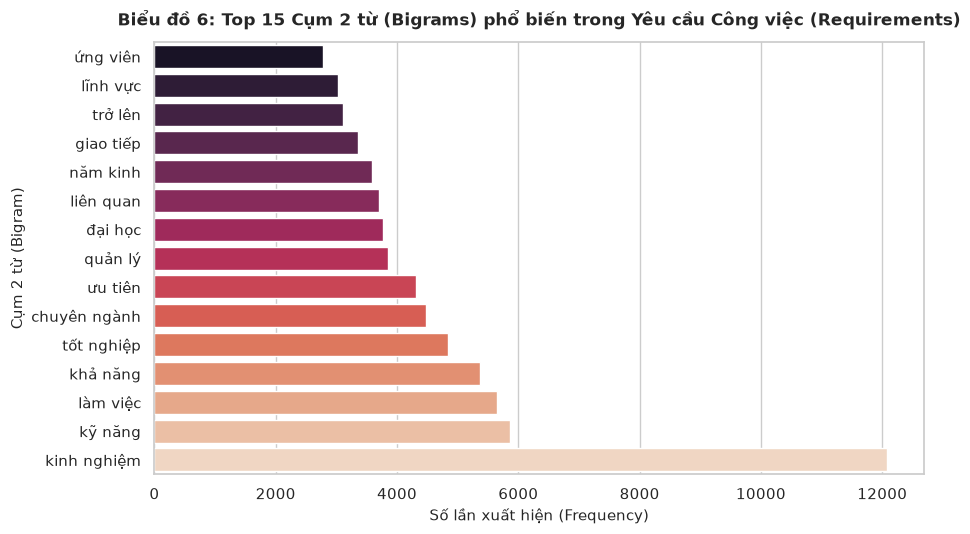

In [7]:
req_texts = []
for r in raw_records:
    req = r.get('requirements_list')
    if isinstance(req, list):
        req_texts.append(' '.join([str(x).lower() for x in req if str(x).strip()]))

vec_bi = CountVectorizer(ngram_range=(2, 2), stop_words=list(stopwords), min_df=5, max_features=15)
X_bi = vec_bi.fit_transform(req_texts)
bi_counts = pd.DataFrame({'Bigram': vec_bi.get_feature_names_out(), 'Count': np.asarray(X_bi.sum(axis=0)).ravel()})
bi_counts = bi_counts.sort_values('Count', ascending=True)

fig, ax = plt.subplots(figsize=(9.5, 5.5))
sns.barplot(data=bi_counts, y='Bigram', x='Count', palette='rocket', ax=ax)
ax.set_title('Biểu đồ 6: Top 15 Cụm 2 từ (Bigrams) phổ biến trong Yêu cầu Công việc (Requirements)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Số lần xuất hiện (Frequency)', fontsize=11)
ax.set_ylabel('Cụm 2 từ (Bigram)', fontsize=11)
plt.tight_layout()
plt.savefig(IMG_DIR / 'nlp_bigrams_requirements.png', dpi=300)
plt.show()

### 📈 Phân tích Biểu đồ 6: Cụm từ trong yêu cầu tuyển dụng (Bigrams)
* **Quan sát thực nghiệm (Empirical Findings)**:
  - Các cụm từ xuất hiện dày đặc nhất gồm: *"kinh nghiệm làm"*, *"làm việc nhóm"*, *"giao tiếp tốt"*, *"tư duy logic"*, *"khả năng tự"*, *"tiếng anh giao tiếp"*.
  - Nhóm yêu cầu kỹ năng mềm (Soft Skills) và thái độ làm việc xuất hiện ở tần suất tương đương, thậm chí cao hơn một số yêu cầu kỹ thuật cụ thể.
* **Nguyên nhân thị trường (Market Context)**:
  - Trong môi trường phát triển phần mềm theo mô hình Agile/Scrum, khả năng phối hợp liên chức năng (Cross-functional collaboration) và tự học giải quyết vấn đề mới là yếu tố quyết định năng suất của kỹ sư.
* **Hàm ý thực tiễn (Actionable Takeaway)**:
  - Ứng viên công nghệ không nên xem nhẹ kỹ năng mềm. Kỹ năng giao tiếp và khả năng làm việc nhóm cần được thể hiện rõ nét trong CV và qua các dự án thực tế.

---
## 6. Khảo Sát Chế Độ Đãi Ngộ & Phúc Lợi Tuyển Dụng (`benefits_list`)
Thống kê tỷ lệ các chế độ phúc lợi được doanh nghiệp công bố để thu hút nhân tài.

C:\Users\DELL\AppData\Local\Temp\ipykernel_18948\2685887662.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_ben, y='Benefit', x='Percentage', palette='flare', ax=ax)
C:\Users\DELL\AppData\Local\Temp\ipykernel_18948\2685887662.py:21: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


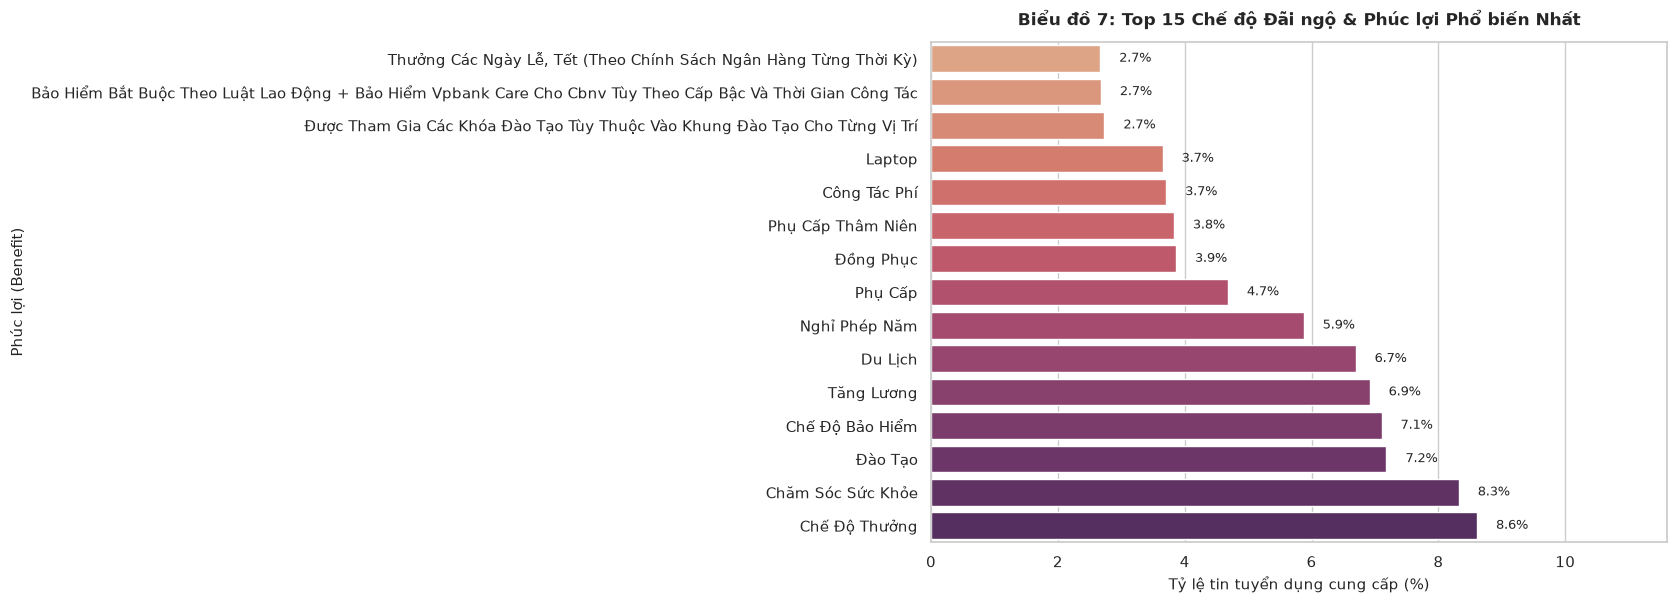

In [8]:
benefit_counter = Counter()
for r in raw_records:
    b = r.get('benefits_list')
    if isinstance(b, list):
        for item in set([str(x).strip().title() for x in b if str(x).strip()]):
            benefit_counter[item] += 1

top15_ben = benefit_counter.most_common(15)
df_ben = pd.DataFrame(top15_ben, columns=['Benefit', 'Count'])
df_ben['Percentage'] = df_ben['Count'] / total_jobs * 100
df_ben = df_ben.sort_values('Count', ascending=True)

fig, ax = plt.subplots(figsize=(9.5, 6.5))
sns.barplot(data=df_ben, y='Benefit', x='Percentage', palette='flare', ax=ax)
ax.set_title('Biểu đồ 7: Top 15 Chế độ Đãi ngộ & Phúc lợi Phổ biến Nhất', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Tỷ lệ tin tuyển dụng cung cấp (%)', fontsize=11)
ax.set_ylabel('Phúc lợi (Benefit)', fontsize=11)
for i, p in enumerate(df_ben['Percentage']):
    ax.annotate(f'{p:.1f}%', (p + 0.3, i), va='center', fontsize=9)
ax.set_xlim(0, max(df_ben['Percentage']) + 3)
plt.tight_layout()
plt.savefig(IMG_DIR / 'benefits_top_bar.png', dpi=300)
plt.show()

### 📈 Phân tích Biểu đồ 7: Chế độ đãi ngộ & phúc lợi
* **Quan sát thực nghiệm (Empirical Findings)**:
  - Bộ 3 phúc lợi cơ bản dẫn đầu: **Chế độ bảo hiểm**, **Chăm sóc sức khỏe** (Bảo hiểm sức khỏe cao cấp), và **Chế độ thưởng** (Lương tháng 13, Thưởng dự án).
  - Tiếp theo là các gói đãi ngộ nâng cao trải nghiệm nhân viên: **Đào tạo**, **Tăng lương định kỳ**, **Du lịch hàng năm**, và **Nghỉ phép năm**.
* **Nguyên nhân thị trường (Market Context)**:
  - Cạnh tranh nhân sự IT gay gắt khiến các quyền lợi cơ bản theo luật lao động trở thành mặc định; các công ty phải bổ sung bảo hiểm sức khỏe tư nhân và ngân sách đào tạo chứng chỉ quốc tế để giữ chân lập trình viên.

---
## 🎯 Kết Luận Từ Chuyên Đề EDA 2
1. **Tech Stack**: SQL, Java, Python, JavaScript và Docker là nền tảng cốt lõi định hình thị trường IT Việt Nam.
2. **Địa lý**: TP.HCM và Hà Nội là hai cực thu hút việc làm chủ đạo (~85%).
3. **Kỹ năng mềm & Ngoại ngữ**: Tiếng Anh và kỹ năng làm việc nhóm là điểm phân loại ứng viên giữa các phân khúc thu nhập.